# AI651 Assignment 3 · Questions 1–6

**Student ID** 25280097

# Question 1 · Neighbor aggregation

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

## Q1(a) · Affine messages

Each neighbor has a reading \(x\). Before adding the readings together, we turn each one into a message using the same rule:
\[
\phi(x)=wx+c.
\]
If node \(v\) has \(n_v\) neighbors and their readings add up to \(S_v\), then the messages add up to
\[
\text{Total message}=wS_v+cn_v.
\]
The \(wS_v\) term comes from multiplying each reading by \(w\). The \(cn_v\) term comes from adding \(c\) once for each neighbor. So if two neighborhoods have the same number of neighbors and the same sum of readings, they give the same total message for any \(w\) and \(c\). The final function \(\rho\) receives that same total and gives the same output.

Example
Neighbor readings	Number of neighbors	Sum of readings	Number of steady neighbors
\(-1,+1\)	2	0	0
\(0,0\)	2	0	2


Both neighborhoods give the total message \(w(0)+c(2)=2c\). Since \(\rho\) receives \(2c\) in both cases, it cannot tell how many neighbors are steady.

## Q1(b) · Verify the count encoding

In [2]:
import numpy as np

K = 8
base = K + 1

# Columns count slowing, steady, and speeding-up neighbors.
counts = np.indices((base, base, base)).reshape(3, -1).T
total = counts.sum(axis=1)
counts = counts[(total >= 1) & (total <= K)]

encoded = counts @ np.array([1, base, base**2])
decoded = np.column_stack([
    encoded % base,
    (encoded // base) % base,
    encoded // base**2,
])

assert np.unique(encoded).size == len(counts)
np.testing.assert_array_equal(decoded, counts)

print(f"Verified {len(counts)} distinct count triples.")

Verified 164 distinct count triples.


## Q1(c) · What can sum, mean, and max tell us?

Each neighbor sends a one-hot vector. The three positions represent **slowing, steady, and speeding up**, in that order.

- **Sum** gives the count in each category.
- **Mean** gives the fraction of neighbors in each category.
- **Max** gives 1 for each category that appears at least once and 0 otherwise.

| Question | Sum | Mean | Max |
|---|---|---|---|
| How many neighbors are steady? | **Yes.** Read the steady coordinate. | **No.** The steady fraction alone does not determine the count. See Example 1. | **No.** The steady coordinate only shows whether the category appears. See Example 1. |
| Are more than half of the neighbors slowing? | **Yes.** Add the three counts to get the total. Check whether the slowing count is greater than half that total. | **Yes.** Check whether the slowing coordinate is greater than 0.5. | **No.** The vector only shows which categories appear. See Example 2. |
| Is any neighbor slowing? | **Yes.** Check whether the slowing count is greater than 0. | **Yes.** Check whether the slowing fraction is greater than 0. | **Yes.** Check whether the slowing coordinate equals 1. |

**Example 1 · Counting steady neighbors with mean or max**

Compare `[0]` with `[0, 0]`. The first neighborhood has **1** steady neighbor and the second has **2**. Both produce the vector `(0, 1, 0)` under mean and under max. Since the aggregate is identical, each method cannot distinguish the two counts.

**Example 2 · Detecting a slowing majority with max**

Compare `[-1, -1, 0]` with `[-1, 0, 0]`. Both produce the max vector `(1, 1, 0)` because each contains slowing and steady neighbors. In the first neighborhood, **2 out of 3** are slowing, so the answer is **yes**. In the second, **1 out of 3** is slowing, so the answer is **no**. Max gives the same vector for both neighborhoods and therefore cannot determine whether slowing is the majority. 

# Question 2 · Ring-road forecasting

## Q2(a) · Fit the symmetric predictor

The slowdown starts at sensor 20, with value 1. After one time step, the true slowdown moves to sensor 19. The symmetric predictor uses weight $a$ for the current sensor and the same weight $b$ for each of its two neighbors.

| Sensor | Predicted value | True value |
|---|---:|---:|
| 19 | $b$ | 1 |
| 20 | $a$ | 0 |
| 21 | $b$ | 0 |

All other sensors have predicted and true values of zero. The total squared error is

$$
L(a,b)=(b-1)^2+a^2+b^2
      =a^2+2(b-\tfrac12)^2+\tfrac12.
$$

The two squared terms are smallest when $a=0$ and $b=\tfrac12$. The minimum squared error is $\tfrac12$.

The fitted predictor sends half of the original spike to sensor 19 and half to sensor 21. Both neighbors receive the same prediction because the layer uses the same weight for both directions. 

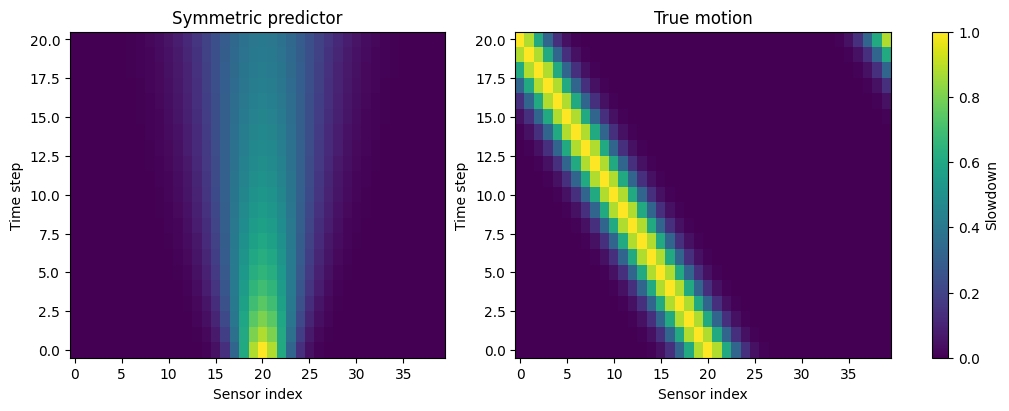

In [4]:
import numpy as np
import matplotlib.pyplot as plt

sensor = np.arange(40)
initial = np.exp(-((sensor - 20) ** 2) / 8)

symmetric = [initial]
true_motion = [initial]

for _ in range(20):
    x = symmetric[-1]
    symmetric.append(0.5 * (np.roll(x, 1) + np.roll(x, -1)))
    true_motion.append(np.roll(true_motion[-1], -1))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)

for ax, values, title in zip(
    axes, (symmetric, true_motion), ("Symmetric predictor", "True motion")
):
    heatmap = ax.imshow(
        values, origin="lower", aspect="auto", vmin=0, vmax=1,
        interpolation="nearest",
    )
    ax.set(title=title, xlabel="Sensor index", ylabel="Time step")

fig.colorbar(heatmap, ax=axes, label="Slowdown")
fig.savefig("q2_ring_road_heatmaps.png", dpi=150)
plt.show()

The symmetric prediction spreads around sensor 20 and its peak gets smaller. The true slowdown keeps its shape and moves one sensor toward lower indices at each step, reaching sensor 0 after 20 steps.  

## Q2(b) · Direction-specific weights

Now the predictor can give different weights to the two neighbors:

$$
\hat{x}_i(t+1)
= w_-x_{i-1}(t) + ax_i(t) + w_+x_{i+1}(t).
$$

The true slowdown moves from sensor $i+1$ to sensor $i$ at each step.
So sensor $i$ should copy the current reading at sensor $i+1$.
Choose $w_-=0$, $a=0$, and $w_+=1$. Substituting gives

$$
\hat{x}_i(t+1)=x_{i+1}(t),
$$

which matches the true update for any initial pattern. For example,
if the spike is at sensor 20, then sensor 19 copies it on the next step.

The kernel weights, in the order $[i-1,\ i,\ i+1]$, are $[0,\ 0,\ 1]$.
Use circular padding so the indices wrap around the ring. For example,
the right neighbor of sensor 39 is sensor 0.

## Q2(c) · Use history with equal neighbor weights

The predictor uses the same weight $b$ for both neighbors and also
uses the previous reading at sensor $i$:

$$
\hat{x}_i(t+1)
= ax_i(t) + b\bigl[x_{i-1}(t)+x_{i+1}(t)\bigr]
+ c x_i(t-1).
$$

### (i) Backward motion

The pattern moves toward lower indices. The reading at sensor $i$
at time $t-1$ has moved to sensor $i-1$ by time $t$, so

$$
x_i(t-1)=x_{i-1}(t).
$$

Choose $a=0$, $b=1$, and $c=-1$. Then

$$
\hat{x}_i(t+1)
= x_{i-1}(t)+x_{i+1}(t)-x_i(t-1)
= x_{i+1}(t).
$$

This matches the true update for backward motion.

### (ii) Forward motion

When the pattern moves toward higher indices, the previous reading
at sensor $i$ has moved to sensor $i+1$. Now $x_i(t-1)=x_{i+1}(t)$.
With the same weights,

$$
\hat{x}_i(t+1)
= x_{i-1}(t)+x_{i+1}(t)-x_i(t-1)
= x_{i-1}(t).
$$

This matches the true update for forward motion.

### (iii) Why history helps

The previous reading at sensor $i$ is now at the neighbor the pattern
moved toward. Subtracting that reading cancels this neighbor's
contribution. The remaining term comes from the other neighbor,
whose reading will move into sensor $i$ next. That is why the same
weights work in both directions.

# Question 3 · LargeST San Diego
In Kaggle, add the [LargeST dataset](https://www.kaggle.com/datasets/liuxu77/largest) using **Add Input**. In Colab, extract the archive under `/content/largest`. Run the inventory cell first, then set the paths in the configuration cell. Use the California adjacency and metadata from the same release so that metadata `ID2` identifies each sensor's matrix position.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path('/kaggle/input') if Path('/kaggle/input').exists() else Path('/content/largest')
for path in sorted(root.rglob('*')):
    if path.suffix in {'.h5', '.hdf', '.hdf5', '.npy', '.npz', '.csv'}:
        print(path)


/kaggle/input/datasets/liuxu77/largest/ca_his_raw_2017.h5
/kaggle/input/datasets/liuxu77/largest/ca_his_raw_2018.h5
/kaggle/input/datasets/liuxu77/largest/ca_his_raw_2019.h5
/kaggle/input/datasets/liuxu77/largest/ca_his_raw_2020.h5
/kaggle/input/datasets/liuxu77/largest/ca_his_raw_2021.h5
/kaggle/input/datasets/liuxu77/largest/ca_meta.csv
/kaggle/input/datasets/liuxu77/largest/ca_rn_adj.npy


In [2]:
data_dir = Path("/kaggle/input/datasets/liuxu77/largest")

traffic_files = {
    2020: data_dir / "ca_his_raw_2020.h5",
    2021: data_dir / "ca_his_raw_2021.h5",
}
metadata_file = data_dir / "ca_meta.csv"
adjacency_file = data_dir / "ca_rn_adj.npy"

# Use "sum" for 5-minute vehicle counts or "mean" for average flow rates.
aggregation = "sum"

for path in [*traffic_files.values(), metadata_file, adjacency_file]:
    if not path.is_file():
        raise FileNotFoundError(path)

# District 11 is the San Diego subset. ID2 gives the position in the CA graph.
metadata = pd.read_csv(metadata_file, dtype={"ID": str})
sd = metadata.loc[metadata["District"].eq(11)].sort_values("ID2")
sensor_ids = pd.Index(sd["ID"], name="sensor_id")
positions = sd["ID2"].to_numpy(dtype=int)

assert len(sensor_ids) == 716, f"Expected 716 sensors, found {len(sensor_ids)}"
assert sensor_ids.is_unique, "Duplicate sensor IDs"
assert len(np.unique(positions)) == 716, "Duplicate adjacency positions"

ca_adj = np.load(adjacency_file, allow_pickle=False)
assert ca_adj.shape == (len(metadata), len(metadata)), ca_adj.shape
assert positions.min() >= 0 and positions.max() < len(ca_adj)

adj = ca_adj[np.ix_(positions, positions)]
assert adj.shape == (716, 716) and np.isfinite(adj).all()

print("Aligned adjacency:", adj.shape)

Aligned adjacency: (716, 716)


## Q3(a) · Data extraction and resampling

I selected 716 District 11 sensors from the 2020 and 2021 traffic files. I treated the five-minute flow readings as interval vehicle counts and summed each group of three to obtain vehicles per 15-minute interval. If any of the three readings was missing, the entire 15-minute bin was marked missing for that sensor.

The five-minute data had 3,095,400 missing readings in 2020 and 4,541,266 in 2021. After resampling, 2,550,289 of 50,246,016 sensor readings were missing (5.08%). I forward-filled within each chronological split and filled leading gaps with each sensor’s 2020 median. For the 19 sensors with no usable 2020 bins, I used the median of the available sensor-level training medians. I retained the original observation mask for later evaluation.

The prepared series contains 70,176 timestamps and 716 sensors. The figure below shows one week of observed traffic at three sensors.

2020 missing five-minute values: 3,095,400
2021 missing five-minute values: 4,541,266
Sensors with no usable 2020 bins: 19
Affected sensor IDs: ['1118458', '1123087', '1118442', '1122601', '1119653', '1115348', '1121722', '1111551', '1115420', '1116593', '1116594', '1115528', '1111552', '1125879', '1108299', '1108323', '1123072', '1123064', '1123069']
Missing 15-minute values before filling: 2,550,289
Split lengths (train, validation, test): 35136 8640 26400
Prepared traffic shape: (70176, 716)


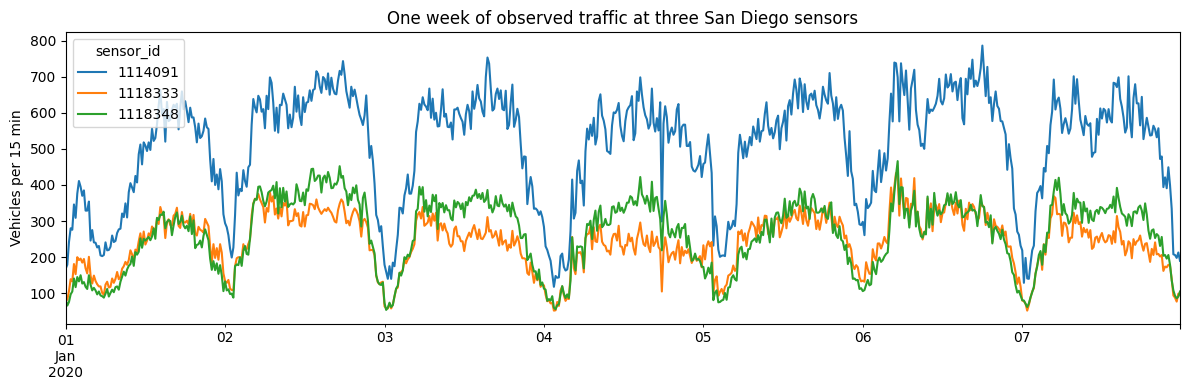

In [4]:
frames = []

for year, path in traffic_files.items():
    raw = pd.read_hdf(path)
    raw.columns = raw.columns.map(str)

    assert raw.columns.is_unique, f"{year}: duplicate sensor columns"
    missing_ids = sensor_ids.difference(raw.columns)
    assert missing_ids.empty, f"{year}: missing sensor IDs {missing_ids.tolist()}"

    # Select the 716 sensors in the same order as the adjacency matrix.
    flow = raw.loc[:, sensor_ids].copy()
    del raw

    flow.index = pd.to_datetime(flow.index)
    assert flow.index.is_unique, f"{year}: duplicate timestamps"
    flow = flow.sort_index()

    expected = pd.date_range(
        start=f"{year}-01-01",
        end=f"{year + 1}-01-01",
        freq="5min",
        inclusive="left",
        tz=flow.index.tz,
    )
    if not flow.index.isin(expected).all():
        raise ValueError(f"{year}: timestamps fall outside the expected five-minute grid")

    flow = flow.reindex(expected).replace([np.inf, -np.inf], np.nan)
    print(f"{year} missing five-minute values: {flow.isna().sum().sum():,}")

    # A usable 15-minute bin must contain all three five-minute readings.
    bins = flow.resample("15min")
    if aggregation == "sum":
        resampled = bins.sum(min_count=3)
    elif aggregation == "mean":
        resampled = bins.mean().where(bins.count().eq(3))
    else:
        raise ValueError("Set aggregation to 'sum' or 'mean' in cell 2.")

    frames.append(resampled.astype("float32"))
    del bins, flow, resampled

# Preserve the original missing values so later cells can save an observation mask.
observed = pd.concat(frames).sort_index()
train = observed.loc["2020"]
valid = observed.loc["2021-01":"2021-03"]
test = observed.loc["2021-04":"2021-12"]

training_medians = train.median()
missing_training = training_medians.isna()
print("Sensors with no usable 2020 bins:", int(missing_training.sum()))
print("Affected sensor IDs:", training_medians.index[missing_training].tolist())

fallback = training_medians.median()
if pd.isna(fallback):
    raise ValueError("No sensor has usable 2020 data. Check the input and resampling.")

# Use the median of available training medians for sensors with no usable 2020 bins.
fill_values = training_medians.fillna(fallback)

# Forward-fill within each split. Fill leading gaps with training-only values.
traffic = pd.concat([
    split.ffill().fillna(fill_values)
    for split in (train, valid, test)
]).astype("float32")

assert traffic.columns.equals(sensor_ids), "Sensor order changed"
assert traffic.index.equals(observed.index), "Timestamp order changed"
assert not traffic.isna().any().any(), "Missing values remain after filling"

print("Missing 15-minute values before filling:", f"{observed.isna().sum().sum():,}")
print("Split lengths (train, validation, test):", len(train), len(valid), len(test))
print("Prepared traffic shape:", traffic.shape)

# Plot observed readings for the first week at three sensors with good coverage.
first_week = train.iloc[:7 * 96]
plot_ids = first_week.notna().sum().nlargest(3).index
first_week.loc[:, plot_ids].plot(
    figsize=(12, 4),
    ylabel="Vehicles per 15 min" if aggregation == "sum" else "Average flow",
    title="One week of observed traffic at three San Diego sensors",
)
plt.tight_layout()
plt.show()

## Q3(b) · Road-distance graph and sensor alignment

I used the District 11 metadata positions (`ID2`) to extract the San Diego submatrix from the California road-distance adjacency. I selected and ordered the traffic columns by the corresponding PeMS sensor IDs, so traffic column `i` and adjacency row and column `i` refer to the same sensor.

The matrix contains **716 nodes**, **17,319 nonzero off-diagonal entries** and **18,035 nonzero entries including the diagonal**. The edge support and weights are asymmetric, so the graph is directed. A nonzero entry in row `i`, column `j` encodes a connection in the supplied road-distance graph. In the model’s aggregation, it allows sensor `j` to contribute to sensor `i`’s representation. The histogram counts nonzero off-diagonal entries in each row.

Nodes: 716
Nonzero entries (including diagonal): 18035
Off-diagonal nonzero entries: 17319
Symmetric weights: False
Symmetric edge support: False


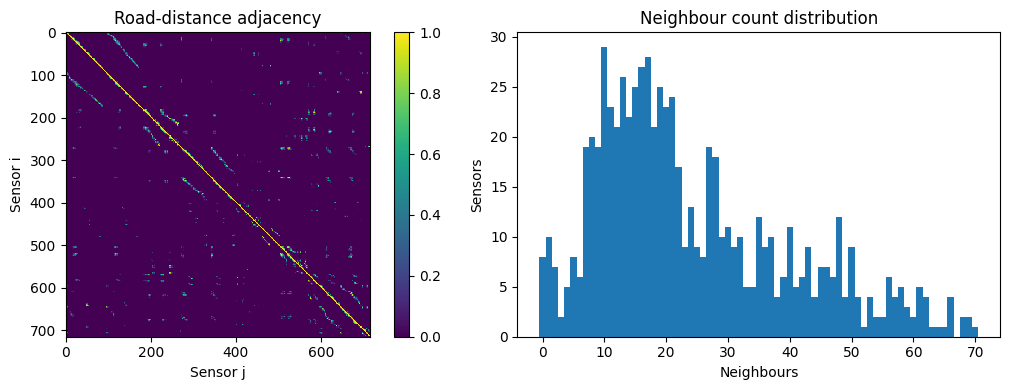

Selected PeMS sensor ID: 1126411
One hop: ['1114805', '1114035', '1108547', '1118707', '1117871', '1108615', '1117818', '1126426', '1114806', '1108711', '1108693', '1111514', '1113486', '1115356', '1115413', '1115432', '1115438', '1116574', '1115528', '1115517']
Exactly two hops: ['1117748', '1113976', '1117741', '1108603', '1117835', '1117717', '1118078', '1108611', '1108613', '1114050', '1108617', '1118496', '1118521', '1108665', '1117683', '1108417', '1117734', '1108605', '1118702', '1108609', '1108728', '1114540', '1111551', '1115420', '1115426', '1111566', '1115444', '1116783', '1114546', '1115555', '1115565', '1111552', '1116165', '1115548', '1111540', '1115572', '1121818', '1114450', '1114457', '1113279', '1111539', '1108331', '1111520', '1121821', '1114463', '1111509', '1121288', '1116112', '1113460', '1108572', '1115921', '1108391', '1115929']


In [5]:
# Q3(b–c): Report matrix entries and use row i for the neighborhood of sensor i.
edge_mask = adj != 0
neighbors = edge_mask.copy()
np.fill_diagonal(neighbors, False)
degree = neighbors.sum(axis=1)
print('Nodes:', len(sensor_ids))
print('Nonzero entries (including diagonal):', np.count_nonzero(edge_mask))
print('Off-diagonal nonzero entries:', np.count_nonzero(neighbors))
print('Symmetric weights:', np.allclose(adj, adj.T))
print('Symmetric edge support:', np.array_equal(edge_mask, edge_mask.T))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot = axes[0].imshow(adj, interpolation='nearest')
axes[0].set(title='Road-distance adjacency', xlabel='Sensor j', ylabel='Sensor i')
fig.colorbar(plot, ax=axes[0])
axes[1].hist(degree, bins=np.arange(degree.max() + 2) - 0.5)
axes[1].set(title='Neighbour count distribution', xlabel='Neighbours', ylabel='Sensors')
plt.tight_layout()
plt.show()

i = int(np.argsort(degree)[len(degree) // 2])
one_hop = np.flatnonzero(neighbors[i])
within_two = set(one_hop) | set(np.flatnonzero(neighbors[one_hop].any(axis=0)))
within_two.discard(i)
print('Selected PeMS sensor ID:', sensor_ids[i])
print('One hop:', sensor_ids[one_hop].tolist())
print('Exactly two hops:', sensor_ids[sorted(within_two - set(one_hop))].tolist())


## Q3(c) · Neighborhoods of PeMS sensor 1126411

**One hop (20 sensors)**  
1114805, 1114035, 1108547, 1118707, 1117871, 1108615, 1117818, 1126426, 1114806, 1108711, 1108693, 1111514, 1113486, 1115356, 1115413, 1115432, 1115438, 1116574, 1115528, 1115517

**Exactly two hops (53 additional sensors)**  
1117748, 1113976, 1117741, 1108603, 1117835, 1117717, 1118078, 1108611, 1108613, 1114050, 1108617, 1118496, 1118521, 1108665, 1117683, 1108417, 1117734, 1108605, 1118702, 1108609, 1108728, 1114540, 1111551, 1115420, 1115426, 1111566, 1115444, 1116783, 1114546, 1115555, 1115565, 1111552, 1116165, 1115548, 1111540, 1115572, 1121818, 1114450, 1114457, 1113279, 1111539, 1108331, 1111520, 1121821, 1114463, 1111509, 1121288, 1116112, 1113460, 1108572, 1115921, 1108391, 1115929

There are 73 distinct neighbors within two hops, excluding sensor 1126411 itself. Direct neighbors can provide early evidence of changes on connected road segments. A second graph layer allows information to travel through an intermediate sensor and can capture changes farther along the network. Repeated aggregation across too many layers can mix unrelated traffic patterns and make nearby sensor representations overly similar, obscuring local changes.

In [8]:
# Keep aligned inputs and the original observation mask for Q4.
output_dir = Path('pa3_outputs')
output_dir.mkdir(exist_ok=True)
np.savez_compressed(
    output_dir / 'largest_sd_15min.npz',
    traffic=traffic.to_numpy(dtype='float32')[..., None],
    observed_mask=observed.notna().to_numpy()[..., None],
    timestamps=traffic.index.astype(str).to_numpy(dtype=str),
    sensor_ids=sensor_ids.to_numpy(dtype=str),
    adjacency=adj.astype('float32'),
)


In [9]:
path = Path("/kaggle/working/pa3_outputs/largest_sd_15min.npz")

with np.load(path, allow_pickle=False) as data:
    print("Saved file:", path)
    print("Traffic:", data["traffic"].shape)
    print("Observation mask:", data["observed_mask"].shape)
    print("Adjacency:", data["adjacency"].shape)

Saved file: /kaggle/working/pa3_outputs/largest_sd_15min.npz
Traffic: (70176, 716, 1)
Observation mask: (70176, 716, 1)
Adjacency: (716, 716)


### Q3(b) · Final graph statistics check

In [21]:
edge_mask = adjacency != 0
off_diagonal = edge_mask.copy()
np.fill_diagonal(off_diagonal, False)

print("Number of nodes:", adjacency.shape[0])
print("Nonzero entries including diagonal:", np.count_nonzero(edge_mask))
print("Nonzero off-diagonal entries:", np.count_nonzero(off_diagonal))
print("Symmetric edge support:", np.array_equal(edge_mask, edge_mask.T))
print("Symmetric weights:", np.allclose(adjacency, adjacency.T))

Number of nodes: 716
Nonzero entries including diagonal: 18035
Nonzero off-diagonal entries: 17319
Symmetric edge support: False
Symmetric weights: False


# Question 4 · Forecasting models

## Q4(a) · Forecasting windows

In [10]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

with np.load(path, allow_pickle=False) as data:
    values = data["traffic"]
    observed_mask = data["observed_mask"]
    adjacency = data["adjacency"]

# Calculate normalization statistics from real 2020 readings only.
train_end = 35_136
val_end = train_end + 8_640
train_observed = values[:train_end][observed_mask[:train_end]]
mean = float(train_observed.mean(dtype=np.float64))
std = float(train_observed.std(dtype=np.float64))
del train_observed

assert np.isfinite(mean) and np.isfinite(std) and std > 0
normalized = (values - np.float32(mean)) / np.float32(std)

HISTORY = 8
HORIZON = 4

class TrafficWindows(Dataset):
    def __init__(self, start, end):
        self.values = torch.from_numpy(normalized[start:end])
        self.mask = torch.from_numpy(observed_mask[start:end])

    def __len__(self):
        return len(self.values) - HISTORY - HORIZON + 1

    def __getitem__(self, index):
        cut = index + HISTORY
        end = cut + HORIZON
        return self.values[index:cut], self.values[cut:end], self.mask[cut:end]

train_ds = TrafficWindows(0, train_end)
val_ds = TrafficWindows(train_end, val_end)
test_ds = TrafficWindows(val_end, len(values))

torch.manual_seed(42)
train_loader = DataLoader(
    train_ds, batch_size=32, shuffle=True,
    generator=torch.Generator().manual_seed(42),
)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

x, y, target_mask = next(iter(val_loader))

print(f"Training mean: {mean:.4f} | Training std: {std:.4f}")
print("Windows (train, validation, test):", len(train_ds), len(val_ds), len(test_ds))
print("Input batch:", tuple(x.shape))
print("Target batch:", tuple(y.shape))
print("Target mask:", tuple(target_mask.shape))

Training mean: 607.1700 | Training std: 483.3516
Windows (train, validation, test): 35125 8629 26389
Input batch: (32, 8, 716, 1)
Target batch: (32, 4, 716, 1)
Target mask: (32, 4, 716, 1)


## Q4(b) and Q5(a) · Fixed-graph STGNN

The same fixed-graph run answers both parts.

In [11]:
from pathlib import Path
from time import perf_counter

from torch import nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
train_loader.generator.manual_seed(42)

EPOCHS = 5
HIDDEN = 16
LR = 1e-3

# Add self-loops and make each row sum to one.
a = torch.as_tensor(adjacency, dtype=torch.float32, device=device)
assert torch.isfinite(a).all() and (a >= 0).all()

a = a + torch.eye(a.shape[0], device=device)
a_fixed = a / a.sum(dim=1, keepdim=True)


class FixedSTGNN(nn.Module):
    def __init__(self, graph):
        super().__init__()
        self.register_buffer("graph", graph)
        self.temporal = nn.Conv1d(1, HIDDEN, kernel_size=HISTORY)
        self.graph_projection = nn.Linear(HIDDEN, HIDDEN, bias=False)
        self.head = nn.Linear(HIDDEN, HORIZON)

    def forward(self, x):
        batch, history, nodes, features = x.shape

        # Run the same temporal encoder on each sensor.
        z = x.permute(0, 2, 3, 1).reshape(batch * nodes, features, history)
        z = self.temporal(z).relu().squeeze(-1).reshape(batch, nodes, HIDDEN)

        # Mix across sensors, then project the aggregated features.
        h = self.graph_projection(self.graph @ z).relu()

        # Match the loader's target shape: [batch, horizon, nodes, 1].
        return self.head(h).transpose(1, 2).unsqueeze(-1)


@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    absolute_sum = torch.zeros((), device=device, dtype=torch.float64)
    squared_sum = torch.zeros_like(absolute_sum)
    observed_count = torch.zeros((), device=device, dtype=torch.long)

    for inputs, targets, mask in loader:
        inputs, targets, mask = (
            tensor.to(device) for tensor in (inputs, targets, mask)
        )
        # Differences in normalized space only need rescaling by std.
        error = (model(inputs) - targets) * std
        error = error.masked_fill(~mask, 0.0)
        absolute_sum += error.abs().sum(dtype=torch.float64)
        squared_sum += error.square().sum(dtype=torch.float64)
        observed_count += mask.sum()

    count = observed_count.item()
    if count == 0:
        raise ValueError("No observed targets in this split.")
    return absolute_sum.item() / count, (squared_sum.item() / count) ** 0.5


model = FixedSTGNN(a_fixed).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

output_dir = Path("/kaggle/working/pa3_outputs")
output_dir.mkdir(parents=True, exist_ok=True)
checkpoint = output_dir / "fixed_stgnn.pt"
best_val_mae = float("inf")
training_seconds = 0.0

print("Device:", device)

for epoch in range(1, EPOCHS + 1):
    model.train()
    start = perf_counter()

    for inputs, targets, mask in train_loader:
        inputs, targets, mask = (
            tensor.to(device) for tensor in (inputs, targets, mask)
        )

        optimizer.zero_grad(set_to_none=True)
        prediction = model(inputs)
        absolute_error = (prediction - targets).abs().masked_fill(~mask, 0.0)
        loss = absolute_error.sum() / mask.sum().clamp_min(1)
        loss.backward()
        optimizer.step()

    if device.type == "cuda":
        torch.cuda.synchronize()
    training_seconds += perf_counter() - start

    val_mae, val_rmse = evaluate(model, val_loader)
    print(f"Epoch {epoch:02d} | Val MAE {val_mae:.3f} | Val RMSE {val_rmse:.3f}")

    if val_mae < best_val_mae:
        best_val_mae = val_mae
        best_epoch = epoch
        torch.save(model.state_dict(), checkpoint)

# Evaluate the checkpoint selected by validation MAE.
model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
val_mae, val_rmse = evaluate(model, val_loader)
test_mae, test_rmse = evaluate(model, test_loader)

print(f"Best epoch: {best_epoch}")
print(f"Validation MAE: {val_mae:.3f} | RMSE: {val_rmse:.3f}")
print(f"Test MAE: {test_mae:.3f} | RMSE: {test_rmse:.3f}")
print(f"Training time excluding evaluation: {training_seconds:.1f} s")
print("Saved checkpoint:", checkpoint)

Device: cpu
Epoch 01 | Val MAE 128.553 | Val RMSE 193.255
Epoch 02 | Val MAE 126.197 | Val RMSE 190.632
Epoch 03 | Val MAE 124.884 | Val RMSE 188.836
Epoch 04 | Val MAE 123.788 | Val RMSE 188.511
Epoch 05 | Val MAE 121.073 | Val RMSE 185.338
Best epoch: 5
Validation MAE: 121.073 | RMSE: 185.338
Test MAE: 135.135 | RMSE: 202.073
Training time excluding evaluation: 136.8 s
Saved checkpoint: /kaggle/working/pa3_outputs/fixed_stgnn.pt


## Q4(c) · Temporal-only baseline

In [12]:
class TemporalOnly(nn.Module):
    def __init__(self):
        super().__init__()
        self.temporal = nn.Conv1d(1, HIDDEN, kernel_size=HISTORY)
        self.head = nn.Linear(HIDDEN, HORIZON)

    def forward(self, x):
        batch, history, nodes, features = x.shape
        z = x.permute(0, 2, 3, 1).reshape(batch * nodes, features, history)
        z = self.temporal(z).relu().squeeze(-1).reshape(batch, nodes, HIDDEN)
        return self.head(z).transpose(1, 2).unsqueeze(-1)


def train_and_evaluate(build_model, name):
    torch.manual_seed(42)
    train_loader.generator.manual_seed(42)

    candidate = build_model().to(device)
    optimizer = torch.optim.Adam(candidate.parameters(), lr=LR)
    checkpoint_path = output_dir / f"{name}.pt"
    best_mae = float("inf")
    elapsed = 0.0

    print("Model:", name, "| Device:", device)

    for epoch in range(1, EPOCHS + 1):
        candidate.train()
        start = perf_counter()

        for inputs, targets, mask in train_loader:
            inputs, targets, mask = (
                tensor.to(device) for tensor in (inputs, targets, mask)
            )
            optimizer.zero_grad(set_to_none=True)
            error = (candidate(inputs) - targets).abs().masked_fill(~mask, 0.0)
            loss = error.sum() / mask.sum().clamp_min(1)
            loss.backward()
            optimizer.step()

        if device.type == "cuda":
            torch.cuda.synchronize()
        elapsed += perf_counter() - start

        validation_mae, validation_rmse = evaluate(candidate, val_loader)
        print(
            f"Epoch {epoch:02d} | Val MAE {validation_mae:.3f} "
            f"| Val RMSE {validation_rmse:.3f}"
        )

        if validation_mae < best_mae:
            best_mae = validation_mae
            best_epoch = epoch
            torch.save(candidate.state_dict(), checkpoint_path)

    candidate.load_state_dict(
        torch.load(checkpoint_path, map_location=device, weights_only=True)
    )
    validation_mae, validation_rmse = evaluate(candidate, val_loader)
    test_mae, test_rmse = evaluate(candidate, test_loader)

    print(f"Best epoch: {best_epoch}")
    print(f"Validation MAE: {validation_mae:.3f} | RMSE: {validation_rmse:.3f}")
    print(f"Test MAE: {test_mae:.3f} | RMSE: {test_rmse:.3f}")
    print(f"Training time excluding evaluation: {elapsed:.1f} s")
    print("Saved checkpoint:", checkpoint_path)

    return candidate, {
        "best_epoch": best_epoch,
        "val_mae": validation_mae,
        "val_rmse": validation_rmse,
        "test_mae": test_mae,
        "test_rmse": test_rmse,
        "training_seconds": elapsed,
    }


temporal_model, temporal_results = train_and_evaluate(TemporalOnly, "temporal_only")

Model: temporal_only | Device: cpu
Epoch 01 | Val MAE 62.723 | Val RMSE 100.996
Epoch 02 | Val MAE 61.634 | Val RMSE 99.423
Epoch 03 | Val MAE 60.639 | Val RMSE 98.052
Epoch 04 | Val MAE 60.155 | Val RMSE 97.071
Epoch 05 | Val MAE 59.984 | Val RMSE 96.943
Best epoch: 5
Validation MAE: 59.984 | RMSE: 96.943
Test MAE: 67.742 | RMSE: 106.987
Training time excluding evaluation: 75.5 s
Saved checkpoint: /kaggle/working/pa3_outputs/temporal_only.pt


# Question 5 · Graph models

## Q5(a) · Fixed graph

See the fixed-graph run under Q4(b).

## Q5(b) · Adaptive graph

Model: adaptive_stgnn | Device: cpu
Epoch 01 | Val MAE 92.555 | Val RMSE 142.711
Epoch 02 | Val MAE 77.518 | Val RMSE 125.589
Epoch 03 | Val MAE 70.616 | Val RMSE 117.327
Epoch 04 | Val MAE 67.336 | Val RMSE 113.138
Epoch 05 | Val MAE 65.582 | Val RMSE 109.319
Best epoch: 5
Validation MAE: 65.582 | RMSE: 109.319
Test MAE: 76.707 | RMSE: 120.438
Training time excluding evaluation: 172.2 s
Saved checkpoint: /kaggle/working/pa3_outputs/adaptive_stgnn.pt


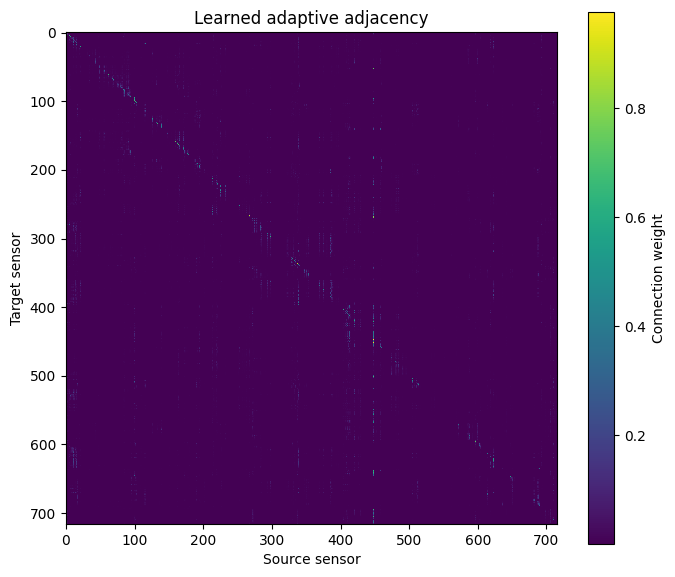

In [13]:
class AdaptiveSTGNN(nn.Module):
    def __init__(self, n_nodes, embedding_dim=16):
        super().__init__()
        self.temporal = nn.Conv1d(1, HIDDEN, kernel_size=HISTORY)
        self.graph_projection = nn.Linear(HIDDEN, HIDDEN, bias=False)
        self.head = nn.Linear(HIDDEN, HORIZON)

        self.node_left = nn.Parameter(torch.randn(n_nodes, embedding_dim) * 0.1)
        self.node_right = nn.Parameter(torch.randn(n_nodes, embedding_dim) * 0.1)

    def adaptive_adjacency(self):
        scores = self.node_left @ self.node_right.T
        return scores.relu().softmax(dim=1)

    def forward(self, x):
        batch, history, nodes, features = x.shape
        z = x.permute(0, 2, 3, 1).reshape(batch * nodes, features, history)
        z = self.temporal(z).relu().squeeze(-1).reshape(batch, nodes, HIDDEN)

        h = self.graph_projection(self.adaptive_adjacency() @ z).relu()
        return self.head(h).transpose(1, 2).unsqueeze(-1)


adaptive_model, adaptive_results = train_and_evaluate(
    lambda: AdaptiveSTGNN(adjacency.shape[0]),
    "adaptive_stgnn",
)

with torch.inference_mode():
    learned_adj = adaptive_model.adaptive_adjacency().cpu().numpy()

np.save(output_dir / "learned_adjacency.npy", learned_adj)

fig, ax = plt.subplots(figsize=(7, 6))
heatmap = ax.imshow(learned_adj, interpolation="nearest", aspect="equal")
ax.set(title="Learned adaptive adjacency", xlabel="Source sensor", ylabel="Target sensor")
fig.colorbar(heatmap, ax=ax, label="Connection weight")
fig.tight_layout()
fig.savefig(output_dir / "adaptive_adjacency.png", dpi=150)
plt.show()

## Q5(c) · Hybrid graph

In [14]:
class HybridSTGNN(AdaptiveSTGNN):
    def __init__(self, fixed_graph, alpha=0.5):
        super().__init__(n_nodes=fixed_graph.shape[0])
        self.register_buffer("fixed_graph", fixed_graph)
        self.alpha = alpha

    def hybrid_adjacency(self):
        return (
            self.alpha * self.fixed_graph
            + (1.0 - self.alpha) * self.adaptive_adjacency()
        )

    def forward(self, x):
        batch, history, nodes, features = x.shape
        z = x.permute(0, 2, 3, 1).reshape(batch * nodes, features, history)
        z = self.temporal(z).relu().squeeze(-1).reshape(batch, nodes, HIDDEN)

        h = self.graph_projection(self.hybrid_adjacency() @ z).relu()
        return self.head(h).transpose(1, 2).unsqueeze(-1)


hybrid_model, hybrid_results = train_and_evaluate(
    lambda: HybridSTGNN(a_fixed, alpha=0.5),
    "hybrid_stgnn",
)

with torch.inference_mode():
    np.save(
        output_dir / "hybrid_adjacency.npy",
        hybrid_model.hybrid_adjacency().cpu().numpy(),
    )

Model: hybrid_stgnn | Device: cpu
Epoch 01 | Val MAE 88.103 | Val RMSE 136.122
Epoch 02 | Val MAE 77.468 | Val RMSE 122.270
Epoch 03 | Val MAE 74.457 | Val RMSE 116.788
Epoch 04 | Val MAE 72.039 | Val RMSE 114.681
Epoch 05 | Val MAE 71.392 | Val RMSE 113.562
Best epoch: 5
Validation MAE: 71.392 | RMSE: 113.562
Test MAE: 80.759 | RMSE: 122.438
Training time excluding evaluation: 181.2 s
Saved checkpoint: /kaggle/working/pa3_outputs/hybrid_stgnn.pt


# Question 6 · Evaluation and graph analysis

## Q6(a) · Forecast comparison and plots

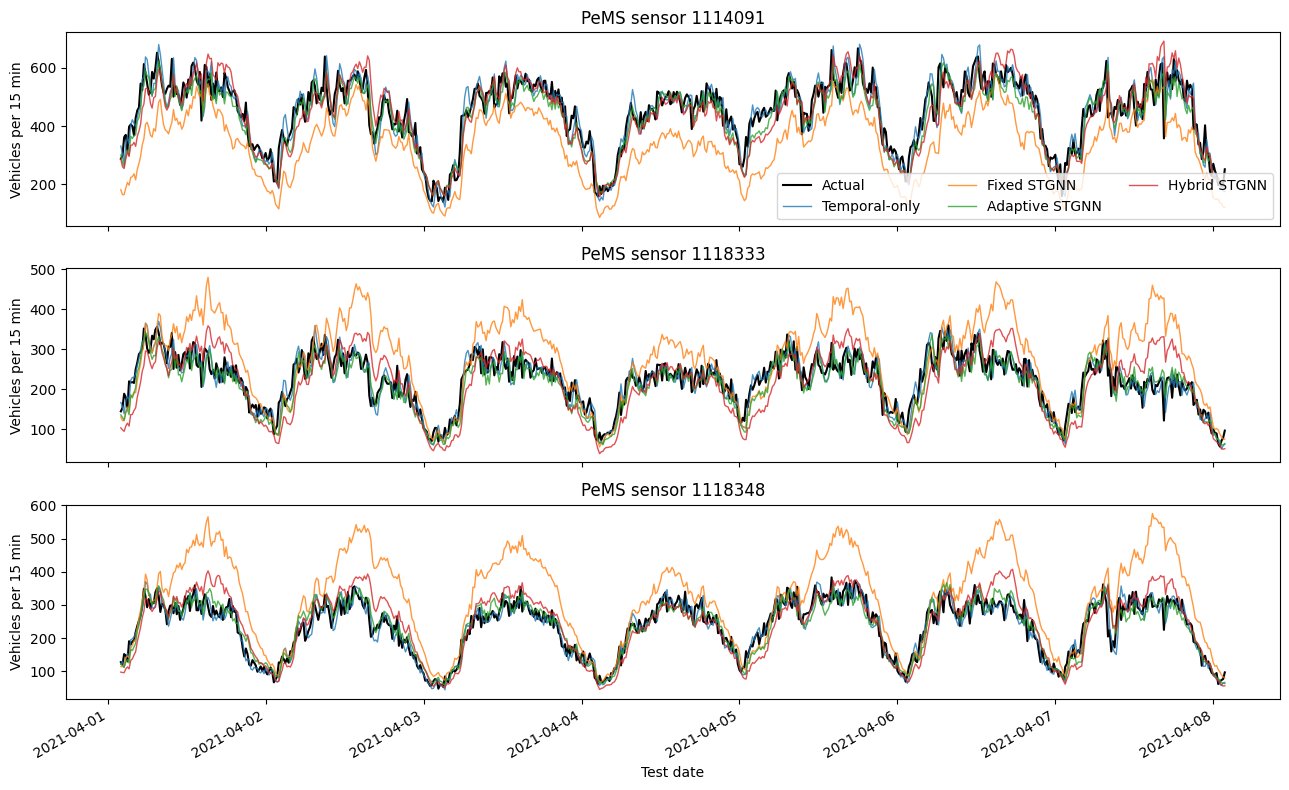

In [15]:
# Select three sensors with the most observed targets in the plotted week.
week_steps = 7 * 96
target_start = val_end + HISTORY
target_stop = target_start + week_steps
sensor_indices = (
    observed.iloc[target_start:target_stop]
    .notna()
    .sum()
    .nlargest(3)
    .index
)
node_indices = sensor_ids.get_indexer(sensor_indices)
timestamps = observed.index[target_start:target_stop]

models_to_plot = {
    "Temporal-only": temporal_model,
    "Fixed STGNN": model,
    "Adaptive STGNN": adaptive_model,
    "Hybrid STGNN": hybrid_model,
}

predictions = {}
with torch.inference_mode():
    for label, predictor in models_to_plot.items():
        predictor.eval()
        batches = []
        for start in range(0, week_steps, 32):
            stop = min(start + 32, week_steps)
            inputs = torch.stack([test_ds[i][0] for i in range(start, stop)])
            forecast = predictor(inputs.to(device))[:, 0, :, 0].cpu().numpy()
            batches.append(forecast[:, node_indices] * std + mean)
        predictions[label] = np.concatenate(batches)

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
for column, (ax, sensor_id) in enumerate(zip(axes, sensor_indices)):
    actual = observed[sensor_id].iloc[target_start:target_stop]
    ax.plot(timestamps, actual, color="black", linewidth=1.5, label="Actual")
    for label, forecast in predictions.items():
        ax.plot(timestamps, forecast[:, column], linewidth=1, alpha=0.8, label=label)
    ax.set_title(f"PeMS sensor {sensor_id}")
    ax.set_ylabel("Vehicles per 15 min" if aggregation == "sum" else "Average flow")

axes[0].legend(ncol=3)
axes[-1].set_xlabel("Test date")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(output_dir / "test_predictions_three_sensors.png", dpi=150)
plt.show()

## Q6(b) · Learned links and geographic proximity

In [17]:
# Rows are receiving sensors; columns are candidate source sensors.
n = len(sensor_ids)
rows = np.arange(n)[:, None]
k = 10

scores = learned_adj.copy()
np.fill_diagonal(scores, -np.inf)
top_neighbors = np.argsort(scores, axis=1)[:, -k:]

road_edges = adjacency != 0
np.fill_diagonal(road_edges, False)
overlap = road_edges[rows, top_neighbors]
road_density = road_edges.sum() / (n * (n - 1))

print(f"Top-{k} learned links also in road graph: "
      f"{overlap.sum():,}/{overlap.size:,} ({overlap.mean():.2%})")
print(f"Road-link rate among all non-self pairs: {road_density:.2%}")
print(f"Top-{k} learned links absent from road graph: {(~overlap).sum():,}")

# Great-circle distances in km, using the same sensor order as the graph.
lat = np.radians(sd["Lat"].to_numpy(dtype=float))
lon = np.radians(sd["Lng"].to_numpy(dtype=float))
dlat = lat[:, None] - lat[None, :]
dlon = lon[:, None] - lon[None, :]
h = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(dlon / 2) ** 2
)
distance_km = 6371 * 2 * np.arcsin(np.sqrt(np.clip(h, 0, 1)))

learned_distances = distance_km[rows, top_neighbors]
all_distances = distance_km[~np.eye(n, dtype=bool)]

print(f"Median distance, top-{k} learned links: {np.nanmedian(learned_distances):.2f} km")
print(f"Median distance, all non-self pairs: {np.nanmedian(all_distances):.2f} km")

Top-10 learned links also in road graph: 933/7,160 (13.03%)
Road-link rate among all non-self pairs: 3.38%
Top-10 learned links absent from road graph: 6,227
Median distance, top-10 learned links: 14.61 km
Median distance, all non-self pairs: 23.02 km


## Q6(c) · Discussion

The temporal-only model had the lowest test error. The adaptive graph performed best among the graph models. Its top learned links overlapped with the road graph more frequently than the all-pairs baseline (13.03% versus 3.38%) and connected sensors with a shorter median straight-line distance (14.61 km versus 23.02 km). Learned weights reflect patterns useful for forecasting and can be influenced by shared commute schedules. Static graph weights cannot adapt to incidents or other changes at inference. The equal-weight hybrid improved on the fixed graph and had higher test error than the adaptive graph.